# Modelado: comparación, evaluación por segmentos y explicabilidad

Este notebook analiza los resultados de `src/modelado.py`, que ajusta los hiperparámetros de
cada modelo con Optuna (validación cruzada de 5 particiones sobre el conjunto de entrenamiento)
y los evalúa una única vez sobre el conjunto de prueba.

Para reproducir los resultados:

```bash
python src/preprocesado.py
python src/modelado.py --pruebas 40
```

Contenido:

1. Comparación de modelos.
2. Calidad de las predicciones del mejor modelo.
3. Rendimiento por tipo de vivienda, localización y tramo de precio.
4. Variables del anuncio (ablación).
5. Explicabilidad con SHAP.
6. Conclusiones, limitaciones y trabajo futuro.

Las figuras se guardan en `doc/figuras/modelado/`.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import shap

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
from preprocesado import preparar  # noqa: E402

RES = RAIZ / "data" / "procesado" / "resultados"
FIGURAS = RAIZ / "doc" / "figuras" / "modelado"
FIGURAS.mkdir(parents=True, exist_ok=True)

AZUL, NARANJA = "#2a78d6", "#eb6834"
TINTA, TINTA_2, REJILLA = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA_2, "axes.titlecolor": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": REJILLA, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "legend.frameon": False,
})
miles = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))
NOMBRES = {"lineal": "Regresión lineal", "random_forest": "Random Forest", "xgboost": "XGBoost",
           "lightgbm": "LightGBM", "catboost": "CatBoost"}

def guardar(fig, nombre):
    fig.savefig(FIGURAS / f"{nombre}.png")
    plt.show()

res = pd.read_csv(RES / "resultados_modelos.csv")
pred = pd.read_csv(RES / "predicciones_prueba.csv", dtype={"id_anuncio": str})
hiper = json.load(open(RES / "hiperparametros.json", encoding="utf-8"))
MEJOR = res.sort_values("CV_RMSE_log").iloc[0]["modelo"]
print("Mejor modelo según validación cruzada:", NOMBRES[MEJOR])

Mejor modelo según validación cruzada: LightGBM


/usr/local/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Comparación de modelos

In [2]:
tabla = res.set_index("modelo").rename(index=NOMBRES)[[
    "CV_RMSE_log", "CV_RMSE_log_desv", "test_RMSE_log", "test_R2_log", "test_MAE_eur",
    "test_RMSE_eur", "test_MAPE_pct", "test_MdAPE_pct", "minutos"]]
tabla.columns = ["RMSE log (CV)", "± desv. (CV)", "RMSE log (prueba)", "R² log (prueba)",
                 "MAE € (prueba)", "RMSE € (prueba)", "MAPE % (prueba)", "MdAPE % (prueba)", "minutos"]
tabla.round({"RMSE log (CV)": 4, "± desv. (CV)": 4, "RMSE log (prueba)": 4, "R² log (prueba)": 3,
             "MAE € (prueba)": 0, "RMSE € (prueba)": 0, "MAPE % (prueba)": 1, "MdAPE % (prueba)": 1,
             "minutos": 1})

,RMSE log (CV),± desv. (CV),RMSE log (prueba),R² log (prueba),MAE € (prueba),RMSE € (prueba),MAPE % (prueba),MdAPE % (prueba),minutos
modelo,,,,,,,,,
LightGBM,0.3053,0.0073,0.2975,0.852,79520.0,175004.0,22.4,16.3,3.4
XGBoost,0.3053,0.0100,0.2987,0.851,79675.0,176267.0,22.3,16.2,2.5
CatBoost,0.3082,0.0103,0.3044,0.845,83579.0,181923.0,23.1,17.8,7.0
Random Forest,0.3255,0.0104,0.3220,0.826,85687.0,195141.0,24.3,17.8,9.5
Regresión lineal,0.3836,0.0084,0.3780,0.761,104680.0,220085.0,30.5,23.2,0.0


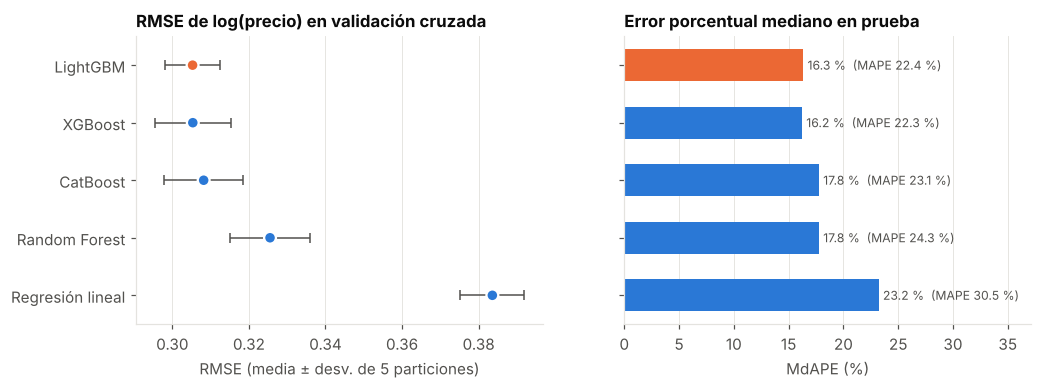

In [3]:
orden = res.sort_values("CV_RMSE_log", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.4), sharey=True)
y = np.arange(len(orden))
colores = [NARANJA if m == MEJOR else AZUL for m in orden["modelo"]]
ax[0].errorbar(orden["CV_RMSE_log"], y, xerr=orden["CV_RMSE_log_desv"], fmt="none", ecolor=TINTA_2,
               capsize=3, linewidth=1)
ax[0].scatter(orden["CV_RMSE_log"], y, color=colores, s=60, zorder=3, edgecolor="white", linewidth=1.5)
ax[0].set(title="RMSE de log(precio) en validación cruzada", xlabel="RMSE (media ± desv. de 5 particiones)")
ax[0].set_yticks(y, [NOMBRES[m] for m in orden["modelo"]]); ax[0].grid(axis="y", visible=False)

ax[1].barh(y, orden["test_MdAPE_pct"], color=colores, height=0.55)
for yi, (md_, mp) in enumerate(zip(orden["test_MdAPE_pct"], orden["test_MAPE_pct"])):
    ax[1].text(md_ + 0.4, yi, f"{md_:.1f} %  (MAPE {mp:.1f} %)", va="center", fontsize=8, color=TINTA_2)
ax[1].set_xlim(0, orden["test_MdAPE_pct"].max() * 1.6)
ax[1].set(title="Error porcentual mediano en prueba", xlabel="MdAPE (%)")
ax[1].grid(axis="y", visible=False)
guardar(fig, "01_comparacion_modelos")

**Lectura.** Los tres modelos de *gradient boosting* son claramente superiores a la regresión lineal y al Random Forest. LightGBM obtiene el menor error en validación cruzada (RMSE de log(precio) 0,3053 ± 0,0073) y se selecciona como modelo final, aunque XGBoost queda prácticamente empatado (0,3053 ± 0,0100) y la diferencia entre ambos está muy por debajo de la variabilidad entre particiones. En el conjunto de prueba, LightGBM alcanza un R² de 0,852 en escala logarítmica, un error porcentual mediano (MdAPE) del 16,3 % y un MAE de unos 79.500 €. Frente a la regresión lineal, reduce el error mediano en casi 7 puntos (del 23,2 % al 16,3 %), lo que confirma que la relación entre las variables y el precio es no lineal, como anticipaba el análisis exploratorio. El RMSE en euros (175.000 €) es mucho mayor que el MAE porque está dominado por las viviendas más caras; por eso se usan como métricas principales las relativas (MdAPE y MAPE).

## 2. Calidad de las predicciones del mejor modelo

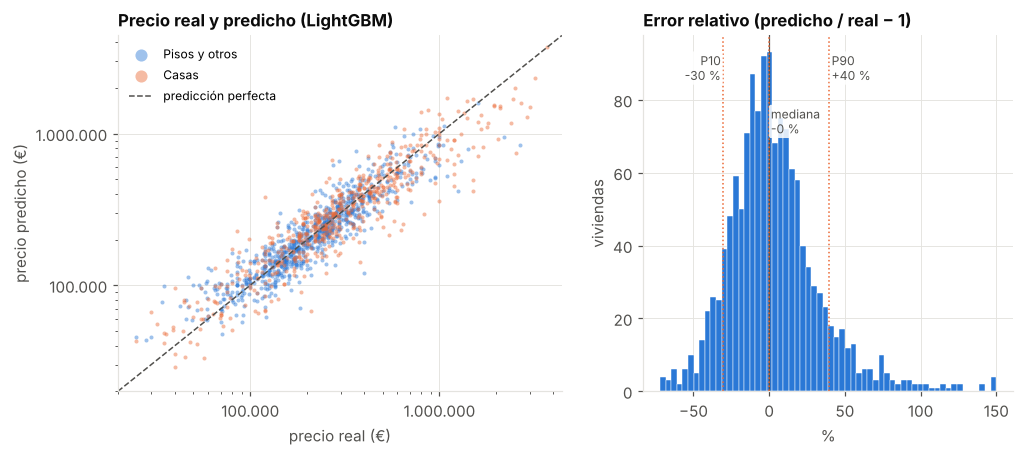

Viviendas con error < 10 %: 31.9% | < 20 %: 58.3% | > 50 %: 9.0%


In [4]:
p = pred.assign(pred=pred[f"pred_{MEJOR}"])
p["error_rel"] = p["pred"] / p["precio_eur"] - 1
p["ape"] = p["error_rel"].abs()
p["grupo"] = np.where(p["tipo_vivienda"] == "casa", "Casas", "Pisos y otros")

fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.2), gridspec_kw=dict(width_ratios=[1.2, 1]))
for g, color in {"Pisos y otros": AZUL, "Casas": NARANJA}.items():
    s = p[p["grupo"] == g]
    ax[0].scatter(s["precio_eur"], s["pred"], s=7, alpha=0.45, color=color, linewidth=0, label=g)
lim = [p[["precio_eur", "pred"]].min().min() * 0.8, p[["precio_eur", "pred"]].max().max() * 1.2]
ax[0].plot(lim, lim, color=TINTA_2, linewidth=1, linestyle="--", label="predicción perfecta")
ax[0].set(xscale="log", yscale="log", xlim=lim, ylim=lim, title=f"Precio real y predicho ({NOMBRES[MEJOR]})",
          xlabel="precio real (€)", ylabel="precio predicho (€)")
ax[0].xaxis.set_major_formatter(miles); ax[0].yaxis.set_major_formatter(miles)
ax[0].legend(loc="upper left", markerscale=3, fontsize=8)

ax[1].hist(p["error_rel"].clip(-1, 1.5) * 100, bins=60, color=AZUL, edgecolor="white", linewidth=0.3)
ax[1].axvline(0, color=TINTA_2, linewidth=0.8)
ytop = ax[1].get_ylim()[1]
for q, lab, ha, alto in [(0.1, "P10", "right", 0.95), (0.5, "mediana", "left", 0.80), (0.9, "P90", "left", 0.95)]:
    v = p["error_rel"].quantile(q) * 100
    ax[1].axvline(v, color=NARANJA, linewidth=1, linestyle=":")
    ax[1].text(v + (-1.5 if ha == "right" else 1.5), ytop * alto, f"{lab}\n{v:+.0f} %", fontsize=8,
               color=TINTA_2, va="top", ha=ha,
               bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.85))
ax[1].set(title="Error relativo (predicho / real − 1)", xlabel="%", ylabel="viviendas")
guardar(fig, "02_real_vs_predicho")

print(f"Viviendas con error < 10 %: {(p['ape'] < 0.10).mean():.1%} | < 20 %: {(p['ape'] < 0.20).mean():.1%} | "
      f"> 50 %: {(p['ape'] > 0.50).mean():.1%}")

**Lectura.** Las predicciones se distribuyen en torno a la diagonal sin un sesgo global (error relativo mediano ≈ 0 %). Un 58 % de las viviendas se predice con un error inferior al 20 % y un 32 % con un error inferior al 10 %; el 80 % central de los errores está entre −30 % y +40 %. Hay una cola de sobrestimaciones grandes (un 9 % de viviendas con error superior al 50 %), concentrada en viviendas baratas, como se ve en la sección siguiente.

## 3. Rendimiento por segmentos

Siguiendo la indicación del tutor, se analiza el error del mejor modelo según el tipo de vivienda,
la localización y el tramo de precio, para detectar limitaciones. Se usa el **error porcentual
mediano (MdAPE)**, robusto a casos extremos, y el **sesgo mediano** (si el modelo tiende a sobrestimar,
valores positivos, o a infravalorar, negativos).

In [5]:
def por_segmento(col, orden=None):
    t = p.groupby(col, observed=True).agg(
        viviendas=("ape", "size"), MdAPE_pct=("ape", lambda s: s.median() * 100),
        MAPE_pct=("ape", lambda s: s.mean() * 100),
        sesgo_mediano_pct=("error_rel", lambda s: s.median() * 100),
        dentro_20_pct=("ape", lambda s: (s < 0.2).mean() * 100))
    return (t.reindex(orden) if orden is not None else t.sort_values("MdAPE_pct")).round(1)

p["tramo_precio"] = pd.qcut(p["precio_eur"], 5, labels=[
    f"Q{i + 1}: {a/1000:,.0f}–{b/1000:,.0f} mil €".replace(",", ".")
    for i, (a, b) in enumerate(zip(*[np.quantile(p["precio_eur"], q) for q in
                                    (np.linspace(0, .8, 5), np.linspace(.2, 1, 5))]))])
p["localizacion"] = np.where(p["es_capital"].astype(str).str.lower().isin(["1", "true"]),
                            "Capital", "Resto de municipios")
p["tamano_municipio"] = pd.cut(p.merge(pd.read_csv(RAIZ / "data/procesado/fotocasa_andalucia_limpio.csv",
                                                   usecols=["id_anuncio", "poblacion_2025"], dtype={"id_anuncio": str}),
                                       on="id_anuncio", how="left")["poblacion_2025"],
                               [0, 10_000, 50_000, 200_000, 1e7],
                               labels=["< 10.000 hab.", "10.000–50.000", "50.000–200.000", "> 200.000"])
segmentos = {
    "grupo": por_segmento("grupo"),
    "tipo_vivienda": por_segmento("tipo_vivienda"),
    "provincia": por_segmento("provincia"),
    "localizacion": por_segmento("localizacion"),
    "tamano_municipio": por_segmento("tamano_municipio", ["< 10.000 hab.", "10.000–50.000", "50.000–200.000", "> 200.000"]),
    "tramo_precio": por_segmento("tramo_precio", list(p["tramo_precio"].cat.categories)),
}
pd.concat({k: v for k, v in segmentos.items()}, names=["segmento", "valor"]).to_csv(
    RES / "error_por_segmento.csv", encoding="utf-8-sig")
segmentos["grupo"]

,viviendas,MdAPE_pct,MAPE_pct,sesgo_mediano_pct,dentro_20_pct
grupo,,,,,
Pisos y otros,807,15.1,20.5,-0.5,62.7
Casas,561,19.0,25.0,0.2,52.0


In [6]:
segmentos['tipo_vivienda']

,viviendas,MdAPE_pct,MAPE_pct,sesgo_mediano_pct,dentro_20_pct
tipo_vivienda,,,,,
estudio,18,8.8,10.8,-0.2,83.3
apartamento,102,13.2,20.1,-2.3,63.7
planta baja,34,14.3,25.0,-3.8,58.8
piso,557,15.3,20.3,-0.5,63.0
ático,50,15.7,22.3,5.6,66.0
casa,561,19.0,25.0,0.2,52.0
dúplex,30,19.3,21.1,-1.7,53.3
sin especificar,16,26.7,24.7,8.5,37.5


In [7]:
segmentos['provincia']

,viviendas,MdAPE_pct,MAPE_pct,sesgo_mediano_pct,dentro_20_pct
provincia,,,,,
Granada,125,13.5,18.5,-0.8,64.0
Cádiz,242,14.9,19.7,-0.4,64.5
Almería,131,15.3,21.8,-5.9,61.1
Sevilla,118,16.7,24.2,-0.7,57.6
Málaga,329,16.7,23.3,3.6,56.2
Huelva,111,17.4,21.4,-1.8,59.5
Córdoba,147,18.2,25.6,1.0,53.7
Jaén,165,19.6,24.2,-3.7,50.9


In [8]:
pd.concat([segmentos['localizacion'], segmentos['tamano_municipio']])

,viviendas,MdAPE_pct,MAPE_pct,sesgo_mediano_pct,dentro_20_pct
Capital,335,15.7,22.3,-4.1,59.4
Resto de municipios,1033,16.4,22.4,0.6,58.0
< 10.000 hab.,144,15.9,22.7,-4.2,60.4
10.000–50.000,503,16.9,22.9,2.6,55.3
50.000–200.000,457,15.6,20.9,-1.3,60.6
> 200.000,264,15.8,23.6,-0.6,59.1


In [9]:
segmentos['tramo_precio']

,viviendas,MdAPE_pct,MAPE_pct,sesgo_mediano_pct,dentro_20_pct
tramo_precio,,,,,
Q1: 25–132 mil €,274,22.9,31.5,13.6,45.6
Q2: 132–199 mil €,276,14.1,18.5,-0.0,66.7
Q3: 199–279 mil €,271,12.9,17.7,-1.3,71.2
Q4: 279–431 mil €,273,15.3,19.2,-1.1,61.9
Q5: 431–3.695 mil €,274,21.4,24.8,-14.3,46.4


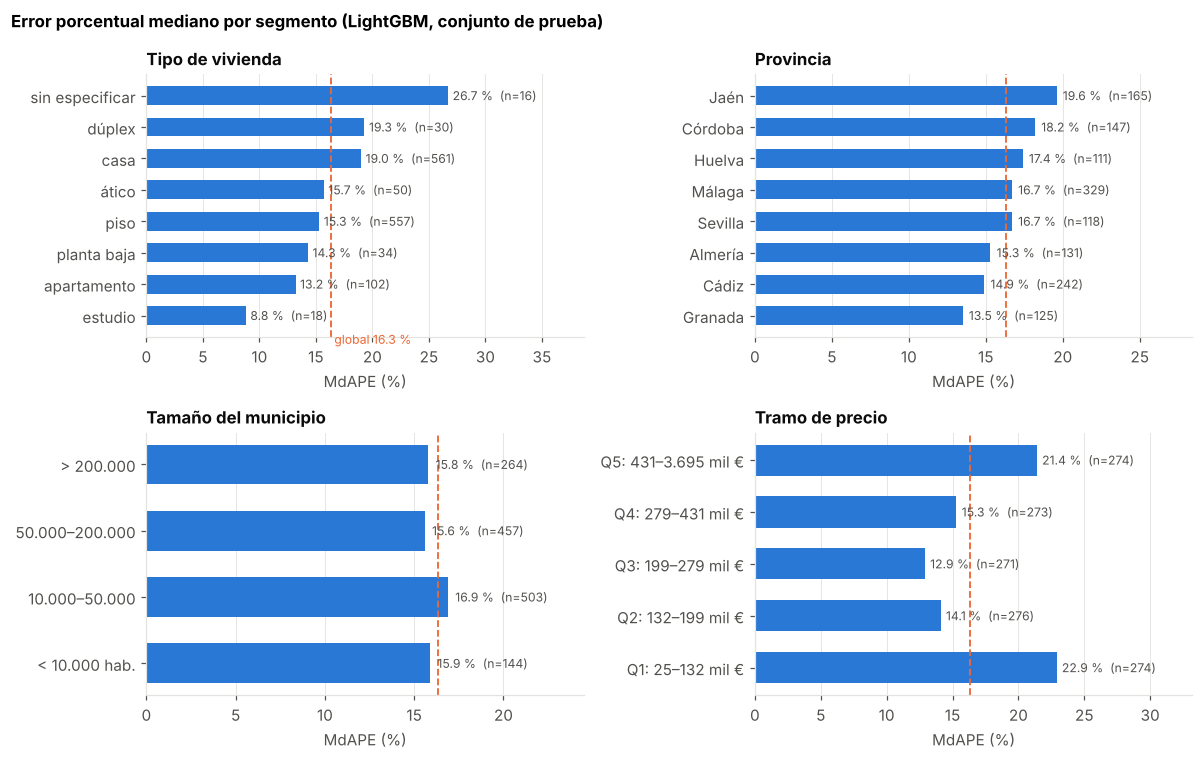

In [10]:
paneles = [("Tipo de vivienda", segmentos["tipo_vivienda"][lambda t: t["viviendas"] >= 15]),
           ("Provincia", segmentos["provincia"]),
           ("Tamaño del municipio", segmentos["tamano_municipio"]),
           ("Tramo de precio", segmentos["tramo_precio"])]
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
global_md = p["ape"].median() * 100
for ax, (titulo, t) in zip(axes.ravel(), paneles):
    y = np.arange(len(t))
    ax.barh(y, t["MdAPE_pct"], color=AZUL, height=0.6)
    for yi, (v, n) in enumerate(zip(t["MdAPE_pct"], t["viviendas"])):
        ax.text(v + 0.4, yi, f"{v:.1f} %  (n={n})", va="center", fontsize=8, color=TINTA_2)
    ax.axvline(global_md, color=NARANJA, linewidth=1.2, linestyle="--")
    ax.set_yticks(y, t.index); ax.grid(axis="y", visible=False)
    ax.set_xlim(0, max(t["MdAPE_pct"].max(), global_md) * 1.45)
    ax.set(title=titulo, xlabel="MdAPE (%)")
axes[0, 0].text(global_md, -0.9, f" global {global_md:.1f} %", color=NARANJA, fontsize=8)
fig.suptitle(f"Error porcentual mediano por segmento ({NOMBRES[MEJOR]}, conjunto de prueba)",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
guardar(fig, "03_error_por_segmento")

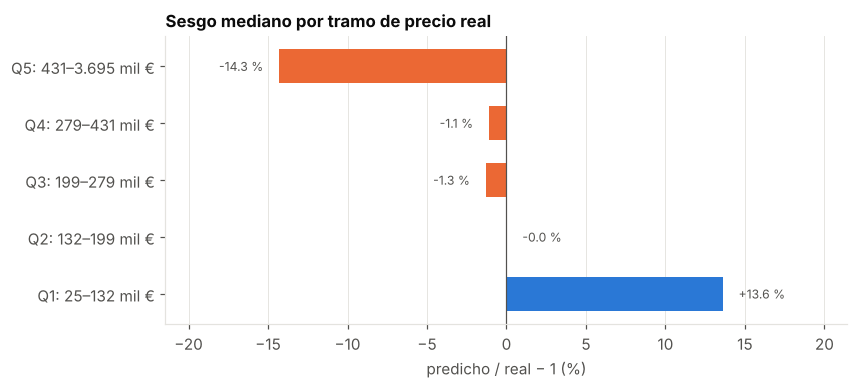

In [11]:
t = segmentos["tramo_precio"]
fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(t))
ax.barh(y, t["sesgo_mediano_pct"], color=[NARANJA if v < 0 else AZUL for v in t["sesgo_mediano_pct"]], height=0.6)
for yi, v in enumerate(t["sesgo_mediano_pct"]):
    ax.text(v + (1 if v >= 0 else -1), yi, f"{v:+.1f} %", va="center", ha="left" if v >= 0 else "right",
            fontsize=8, color=TINTA_2)
ax.axvline(0, color=TINTA_2, linewidth=0.8)
lim = max(abs(t["sesgo_mediano_pct"]).max() * 1.5, 5)
ax.set_xlim(-lim, lim)
ax.set_yticks(y, t.index); ax.grid(axis="y", visible=False)
ax.set(title="Sesgo mediano por tramo de precio real", xlabel="predicho / real − 1 (%)")
guardar(fig, "04_sesgo_por_tramo")

**Lectura.** 

- **Tipo de vivienda.** El modelo funciona mejor en pisos y otros (MdAPE 15,1 %) que en casas (19,0 %), y la proporción de viviendas con error inferior al 20 % baja del 63 % al 52 %. Las casas son más heterogéneas (parcela, calidades, ubicación aislada) y la información disponible las describe peor. Los tipos poco frecuentes (dúplex, *sin especificar*) tienen errores mayores, pero con muestras pequeñas.
- **Provincia.** El error oscila entre el 13,5 % de Granada y el 19,6 % de Jaén. Las provincias de interior y con mercados más baratos (Jaén, Córdoba) son las peor predichas, lo que enlaza con el efecto del tramo de precio.
- **Localización.** No hay diferencias relevantes entre capitales (15,7 %) y resto de municipios (16,4 %), ni según el tamaño del municipio (entre el 15,6 % y el 16,9 %): la cobertura territorial lograda permite que el modelo generalice de forma homogénea. En las capitales se observa una ligera infravaloración (sesgo mediano −4,1 %).
- **Tramo de precio.** Es la principal limitación. El error es bajo en los tramos centrales (13–15 %) y sube en los extremos (22,9 % en el quintil más barato y 21,4 % en el más caro), con un sesgo sistemático de **regresión hacia la media**: el modelo sobrestima las viviendas más baratas (+13,6 %) e infravalora las más caras (−14,3 %). Es un comportamiento habitual en modelos de regresión entrenados con pérdida cuadrática, y sugiere que faltan variables que expliquen por qué una vivienda es especialmente barata (estado real, ocupación, necesidad de venta) o especialmente cara (vistas, calidades, primera línea de playa).

## 4. Variables del anuncio (ablación)

El modelo principal no incluye variables que describen el anuncio y no la vivienda (número de fotos,
longitud de la descripción, bajada de precio). Se comprueba su efecto reentrenando el mejor modelo
con los mismos hiperparámetros y las mismas particiones.

In [12]:
ab = pd.read_csv(RES / "ablacion_anuncio.csv").set_index("variante")
ab[["CV_RMSE_log", "CV_RMSE_log_desv", "test_RMSE_log", "test_R2_log", "test_MAPE_pct", "test_MdAPE_pct",
    "test_MAE_eur"]].round(4)

,CV_RMSE_log,CV_RMSE_log_desv,test_RMSE_log,test_R2_log,test_MAPE_pct,test_MdAPE_pct,test_MAE_eur
variante,,,,,,,
sin variables del anuncio,0.3053,0.0073,0.2975,0.8518,22.3505,16.3266,79520.1961
con variables del anuncio,0.3053,0.0091,0.2946,0.8546,22.5387,16.1434,80323.5027


**Lectura.** Añadir las variables del anuncio no mejora el modelo de forma relevante: el error en validación cruzada es idéntico (0,3053) y en prueba las diferencias son mínimas y de signo mixto (MdAPE 16,1 % frente a 16,3 %, pero MAE algo peor). Se confirma la decisión de excluirlas: el modelo final se basa solo en características de la vivienda y de su entorno, sin depender de cómo se redacta o ilustra el anuncio.

## 5. Explicabilidad (SHAP)

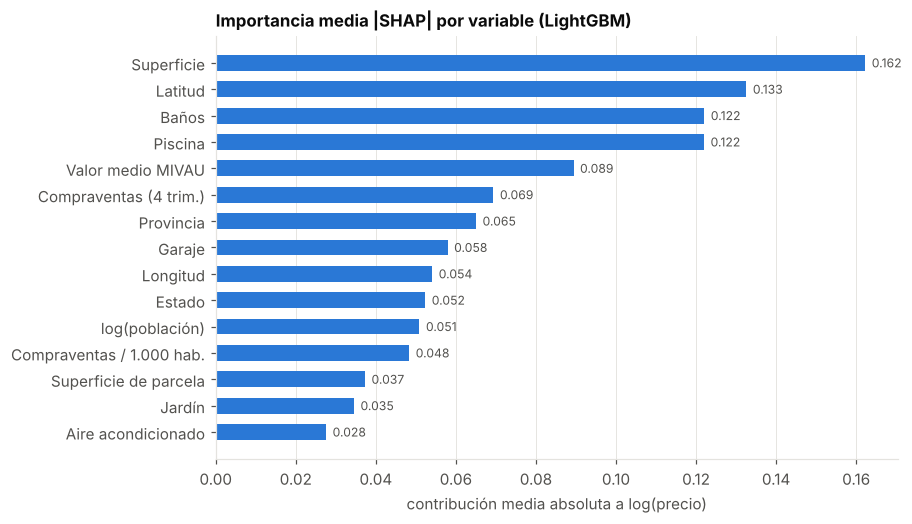

,% del total
superficie_m2,12.0
latitud,9.8
banos,9.0
piscina,9.0
mivau_valor_medio_ref_eur,6.6
mivau_trans_total_4t,5.1
provincia,4.8
parking,4.3
longitud,4.0
estado,3.9


In [13]:
X_train, X_test, y_train, y_test, ctx = preparar()
modelo = joblib.load(RAIZ / "models" / f"{MEJOR}.joblib")
explicador = shap.TreeExplainer(modelo)
valores = explicador(X_test)

# Las columnas one-hot de una misma variable se suman para leer la importancia por variable original
def variable_original(c):
    if c == "log_superficie":          # misma variable en otra escala
        return "superficie_m2"
    for pref in ["tipo_vivienda_", "estado_", "orientacion_", "provincia_"]:
        if c.startswith(pref):
            return pref[:-1]
    return c

grupos = pd.Series([variable_original(c) for c in X_test.columns], index=X_test.columns)
shap_df = pd.DataFrame(valores.values, columns=X_test.columns)
importancia = shap_df.abs().T.groupby(grupos).sum().T.mean().sort_values()

NOMBRES_VAR = {
    "superficie_m2": "Superficie", "log_superficie": "Superficie (log)", "banos": "Baños",
    "habitaciones": "Habitaciones", "latitud": "Latitud", "longitud": "Longitud",
    "mivau_valor_medio_ref_eur": "Valor medio MIVAU", "mivau_trans_por_1000hab": "Compraventas / 1.000 hab.",
    "mivau_trans_total_4t": "Compraventas (4 trim.)", "log_poblacion": "log(población)",
    "antiguedad_anos": "Antigüedad", "planta_num": "Planta", "superficie_terreno_m2": "Superficie de parcela",
    "tipo_vivienda": "Tipo de vivienda", "estado": "Estado", "orientacion": "Orientación",
    "provincia": "Provincia", "es_capital": "Capital", "obra_nueva": "Obra nueva", "piscina": "Piscina",
    "ascensor": "Ascensor", "terraza": "Terraza", "parking": "Garaje", "jardin": "Jardín",
    "aire_acondicionado": "Aire acondicionado", "trastero": "Trastero", "calefaccion": "Calefacción",
    "balcon": "Balcón", "cocina_equipada": "Cocina equipada", "patio": "Patio",
    "puerta_blindada": "Puerta blindada", "electrodomesticos": "Electrodomésticos", "domotica": "Domótica",
    "amueblado": "Amueblado", "alquilado": "Alquilado",
}
top = importancia.tail(15)
fig, ax = plt.subplots(figsize=(8, 5))
y = np.arange(len(top))
ax.barh(y, top.values, color=AZUL, height=0.6)
for yi, v in enumerate(top.values):
    ax.text(v + top.max() * 0.01, yi, f"{v:.3f}", va="center", fontsize=8, color=TINTA_2)
ax.set_yticks(y, [NOMBRES_VAR.get(i, i) for i in top.index]); ax.grid(axis="y", visible=False)
ax.set(title=f"Importancia media |SHAP| por variable ({NOMBRES[MEJOR]})",
       xlabel="contribución media absoluta a log(precio)")
guardar(fig, "05_importancia_shap")
(importancia.sort_values(ascending=False) / importancia.sum() * 100).round(1).head(15).to_frame("% del total")

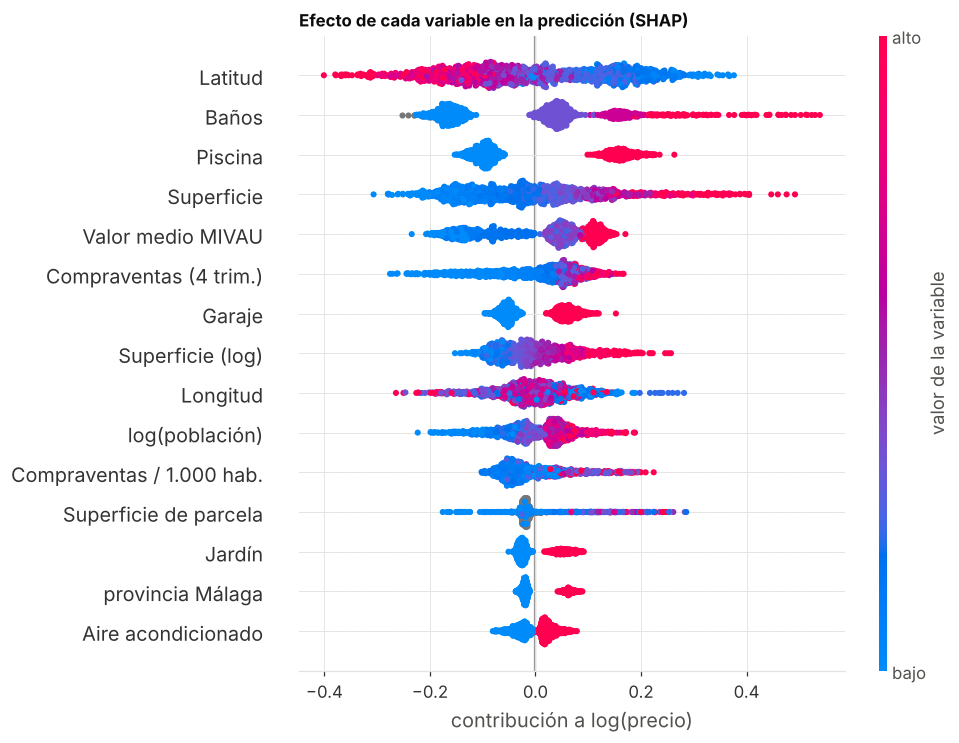

In [14]:
cols_top = [c for c in shap_df.abs().mean().sort_values(ascending=False).index[:15]]
fig = plt.figure(figsize=(8, 6))
shap.plots.beeswarm(valores[:, cols_top], max_display=15, show=False, color_bar_label="valor de la variable")
ax = plt.gca()
ax.set_yticklabels([NOMBRES_VAR.get(t.get_text(), t.get_text().replace("_", " "))
                    for t in ax.get_yticklabels()])
ax.set_title("Efecto de cada variable en la predicción (SHAP)", loc="left", fontweight="bold")
ax.set_xlabel("contribución a log(precio)")
barra = plt.gcf().axes[-1]
barra.set_yticks(barra.get_yticks(), ["bajo", "alto"][:len(barra.get_yticks())])
guardar(plt.gcf(), "06_beeswarm_shap")

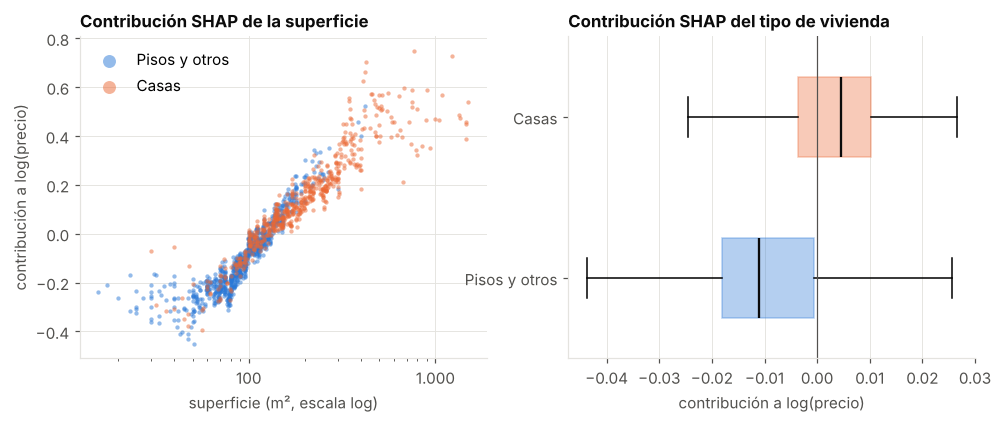

Efecto mediano del tipo: casas +0.005 | pisos -0.011 (en log; diferencia ≈ +2%)


In [15]:
# ¿Recoge el modelo la diferencia entre casas y pisos? Efecto de la superficie según el tipo
sup_cols = [c for c in ["superficie_m2", "log_superficie"] if c in shap_df]
efecto_sup = shap_df[sup_cols].sum(axis=1)
es_casa = (ctx["tipo_vivienda"] == "casa").values
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
for msk, g, color in [(~es_casa, "Pisos y otros", AZUL), (es_casa, "Casas", NARANJA)]:
    ax[0].scatter(X_test.loc[msk, "superficie_m2"], efecto_sup[msk], s=8, alpha=0.5, color=color, linewidth=0, label=g)
ax[0].set(xscale="log", title="Contribución SHAP de la superficie", xlabel="superficie (m², escala log)",
          ylabel="contribución a log(precio)")
ax[0].xaxis.set_major_formatter(miles); ax[0].legend(markerscale=3)

tipo_cols = [c for c in shap_df if c.startswith("tipo_vivienda_")]
efecto_tipo = shap_df[tipo_cols].sum(axis=1)
datos = [efecto_tipo[~es_casa], efecto_tipo[es_casa]]
bp = ax[1].boxplot(datos, orientation="horizontal", tick_labels=["Pisos y otros", "Casas"], showfliers=False,
                   widths=0.5, patch_artist=True, medianprops=dict(color=TINTA, linewidth=1.5))
for patch, color in zip(bp["boxes"], [AZUL, NARANJA]):
    patch.set(facecolor=color, alpha=0.35, edgecolor=color)
ax[1].axvline(0, color=TINTA_2, linewidth=0.8)
ax[1].set(title="Contribución SHAP del tipo de vivienda", xlabel="contribución a log(precio)")
ax[1].grid(axis="y", visible=False)
guardar(fig, "07_superficie_y_tipo_shap")
print(f"Efecto mediano del tipo: casas {np.median(efecto_tipo[es_casa]):+.3f} | pisos {np.median(efecto_tipo[~es_casa]):+.3f} "
      f"(en log; diferencia ≈ {np.exp(np.median(efecto_tipo[es_casa]) - np.median(efecto_tipo[~es_casa])) - 1:+.0%})")

**Lectura.** 

- Las variables más influyentes son la **superficie**, la **ubicación** (latitud, y en menor medida longitud y provincia), el número de **baños** y la **piscina**, seguidas de las variables de contexto del MIVAU (valor medio de compraventa y número de compraventas) y la población del municipio. Las variables de enriquecimiento aportan en conjunto una parte importante de la explicación, lo que justifica su incorporación.
- La **latitud** tiene un efecto negativo: a mayor latitud (más al norte, hacia el interior y Sierra Morena), menor precio; recoge el gradiente costa–interior observado en el análisis exploratorio.
- El efecto de la **superficie** es creciente y casi lineal en escala logarítmica, con rendimientos decrecientes por encima de unos 400 m², y es **muy similar para casas y pisos**.
- La variable **tipo de vivienda**, en cambio, apenas contribuye por sí misma (±2 %). Esto no significa que el modelo ignore la diferencia entre casas y pisos, sino que la recoge a través de variables que las caracterizan mejor: superficie de parcela, jardín, piscina, planta o localización. Es coherente con la indicación del tutor de que un único modelo puede adaptarse a ambos grupos, aunque el error sigue siendo mayor en casas.
- Equipamientos como el garaje, el jardín o el aire acondicionado tienen efectos positivos y moderados, en la dirección esperada.

## 6. Conclusiones, limitaciones y trabajo futuro

**Resultados principales**

1. LightGBM es el modelo con mejor rendimiento (R² log 0,852; MdAPE 16,3 %; MAE ≈ 79.500 €), prácticamente empatado con XGBoost y claramente por delante de Random Forest y de la regresión lineal.
2. Un único modelo para todos los tipos de vivienda es suficiente: la diferencia entre casas y pisos se recoge a través de las variables que las caracterizan.
3. La ubicación y las variables de contexto (MIVAU, INE) están entre las más relevantes, lo que valida el enriquecimiento con fuentes oficiales.
4. Las variables del anuncio no aportan mejora y se excluyen.

**Limitaciones**

- **Regresión hacia la media**: se sobrestiman las viviendas baratas y se infravaloran las caras (±14 % de sesgo en los quintiles extremos).
- **Peor rendimiento en casas** (MdAPE 19,0 % frente a 15,1 %) y en provincias de interior como Jaén y Córdoba.
- **Precio de oferta**, no de transacción: el modelo aprende lo que piden los anunciantes, que según el MIVAU está entre 1,2 y 1,7 veces por encima del precio de compraventa.
- **Muestra de un único portal y periodo** (septiembre–noviembre de 2026), sin dimensión temporal y con anuncios retirados antes de la consulta del detalle en la extracción provincial.
- **Variables incompletas**: la planta, la antigüedad y la orientación tienen muchos ausentes, y no se dispone de calidades, vistas o distancia a la playa.

**Trabajo futuro**

- Incorporar variables de entorno a partir de las coordenadas: distancia a la costa y al centro urbano, servicios cercanos, renta por sección censal (INE).
- Extraer información del texto de la descripción (vistas, calidades, reformas) mediante técnicas de procesamiento de lenguaje natural.
- Tratar el sesgo en los extremos: modelos específicos o ponderación por tramo de precio, o funciones de pérdida robustas.
- Ampliar la extracción en el tiempo para estudiar la evolución de precios y la diferencia entre precio de oferta y de cierre.
- Estimar intervalos de predicción (por ejemplo, regresión cuantílica) para acompañar cada estimación de su incertidumbre.